# Segmentación de clientes de una tienda en línea mediante K-Means

**Proyecto integrador — Minería de datos**
Segmentación de datos mediante K-Means y desarrollo de un dashboard interactivo.

| Elemento | Detalle |
|---|---|
| Temática | Comercio electrónico / marketing analítico |
| Dataset | *Online Retail* — UCI Machine Learning Repository (Chen, 2015) |
| Algoritmo | K-Means (Scikit-learn) |
| Herramientas | Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, Streamlit |

**Contenido**

1. Selección del tema y planteamiento del problema
2. Obtención y exploración del dataset
3. Limpieza y preparación de datos
4. Implementación del algoritmo K-Means
5. Análisis e interpretación de resultados
6. Exportación de resultados para el dashboard

## Parte 1. Selección del tema y planteamiento del problema

### 1.1 Temática
**Comercio electrónico minorista.** El caso de estudio es una tienda en línea con sede en Reino Unido que vende
artículos de regalo y decoración, principalmente a otros negocios (mayoristas y pequeños comercios) y a
clientes particulares de unos 37 países.

### 1.2 Problema
La tienda trata a todos sus clientes de la misma manera: mismas campañas, mismos descuentos y la misma atención.
Sin embargo, sus clientes son muy distintos entre sí: algunos compran cada semana y gastan miles de libras,
mientras que otros compraron una sola vez hace meses y no han vuelto. **Sin una segmentación, la empresa no sabe
a quién retener, a quién reactivar ni en quién conviene invertir su presupuesto de marketing**, lo que se traduce
en campañas poco rentables y en la pérdida silenciosa de clientes valiosos.

### 1.3 Objetivo general
Identificar segmentos de clientes con comportamientos de compra similares mediante el algoritmo K-Means, a
partir de las variables de Recencia, Frecuencia y Valor Monetario (RFM), y presentar los resultados en un
dashboard interactivo que apoye la toma de decisiones comerciales.

### 1.4 Objetivos específicos
1. Depurar y transformar el registro de transacciones en un perfil por cliente (variables RFM y complementarias).
2. Determinar el número óptimo de clústeres comparando al menos cinco valores de K con el método del codo, el
   coeficiente de silueta y el índice de Davies-Bouldin.
3. Caracterizar, nombrar y comparar cada segmento obtenido con estadísticas descriptivas y sus centroides.
4. Proponer recomendaciones comerciales específicas para cada segmento.
5. Construir un dashboard interactivo (Streamlit) con KPI, gráficas y filtros para explorar los segmentos.

### 1.5 Justificación
* En marketing se suele citar que **retener a un cliente cuesta menos que conseguir uno nuevo**, y que una
  pequeña parte de los clientes concentra la mayor parte de los ingresos (principio de Pareto). Detectar
  estos grupos permite enfocar el presupuesto donde más rinde.
* El análisis RFM es una técnica muy usada en la industria y fácil de explicar al área comercial. K-Means
  la complementa con segmentos **definidos por los datos** en lugar de umbrales arbitrarios.
* El dashboard convierte el modelo en una herramienta que pueden usar personas sin conocimientos de programación.

### 1.6 Patrones que se pretenden identificar con K-Means
Se espera encontrar grupos como:
* **Clientes de alto valor**: compran seguido, recientemente y gastan mucho.
* **Clientes regulares**: compran con cierta frecuencia y gasto medio, pero podrían estar enfriándose.
* **Clientes nuevos u ocasionales**: compraron hace poco, pero pocas veces y por montos bajos.
* **Clientes inactivos o perdidos**: su última compra fue hace mucho tiempo.

K-Means agrupará a los clientes por su cercanía en el espacio (Recencia, Frecuencia, Monetario), y el análisis
posterior confirmará o corregirá estas hipótesis.

## Parte 2. Obtención y exploración del dataset

### 2.1 Fuente de los datos
* **Nombre:** Online Retail
* **Fuente:** UCI Machine Learning Repository — <https://archive.ics.uci.edu/dataset/352/online+retail>
* **Cita:** Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33
* **Licencia:** Creative Commons Attribution 4.0 (CC BY 4.0)
* **Periodo:** 01/12/2010 al 09/12/2011
* **Contenido:** 541,909 líneas de factura (registros) y 8 variables.

El archivo original es un Excel (`Online Retail.xlsx`, ~23 MB). Para que el repositorio sea ligero y la carga
sea rápida se convirtió, sin modificar ningún valor, a un CSV comprimido (`data/raw/online_retail.csv.gz`) con
el script `scripts/descargar_datos.py`. El notebook lo lee con `pd.read_csv()`.

| Variable | Descripción |
|---|---|
| `InvoiceNo` | Número de factura. Si empieza con **C** es una cancelación/devolución |
| `StockCode` | Código del producto |
| `Description` | Nombre del producto |
| `Quantity` | Unidades por línea de factura |
| `InvoiceDate` | Fecha y hora de la factura |
| `UnitPrice` | Precio unitario en libras esterlinas (£) |
| `CustomerID` | Identificador del cliente |
| `Country` | País de residencia del cliente |

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# Rutas del proyecto (funciona si el notebook se ejecuta desde /notebooks o desde la raíz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "online_retail.csv.gz"
PROCESSED = ROOT / "data" / "processed"
FIGS = ROOT / "reports" / "figuras"
MODELS = ROOT / "models"
for p in (PROCESSED, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

def guardar(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", bbox_inches="tight", dpi=120)

### 2.2 Importación del dataset con `read_csv()`

In [2]:
df_raw = pd.read_csv(RAW, dtype={"InvoiceNo": str, "StockCode": str})
print("Dataset cargado:", RAW.name)

Dataset cargado: online_retail.csv.gz


### 2.3 Primeros 10 registros

In [3]:
df_raw.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,"17,850.00",United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,"17,850.00",United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,"17,850.00",United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,"13,047.00",United Kingdom


### 2.4 Dimensiones, columnas y tipos de datos

In [4]:
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas\n")
print("Columnas:", list(df_raw.columns), "\n")
df_raw.info()

Dimensiones: 541,909 filas x 8 columnas

Columnas: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country'] 

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 69.3 MB


**Observaciones sobre los tipos de datos**
* `InvoiceDate` se leyó como texto (`object`/`str`): debe convertirse a `datetime`.
* `CustomerID` se leyó como `float64` porque tiene valores nulos; es un identificador y debe ser entero.
* `InvoiceNo` y `StockCode` se forzaron a texto porque contienen letras (`C536379`, `85123A`).

### 2.5 Estadísticas descriptivas

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,"541,909.00",9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
UnitPrice,"541,909.00",4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"
CustomerID,"406,829.00","15,287.69","1,713.60","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00"


In [6]:
df_raw.describe(include=['object', 'string']).T

,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
InvoiceDate,541909,23260,2011-10-31 14:41:00,1114
Country,541909,38,United Kingdom,495478


**Lectura de las estadísticas**
* `Quantity` tiene un mínimo de **-80,995** y un máximo de **80,995**: es la misma compra registrada y luego
  cancelada. Las cantidades negativas corresponden a devoluciones.
* `UnitPrice` tiene valores negativos (-11,062.06) y valores de 0: ajustes contables y regalos, no ventas reales.
* La mediana de `Quantity` (3) y de `UnitPrice` (£2.08) está muy lejos de sus máximos: las distribuciones
  están **muy sesgadas a la derecha**, con valores atípicos extremos.
* Hay 25,900 facturas, 4,070 códigos de producto (pero 4,223 descripciones: un primer indicio de
  inconsistencias) y 38 valores de país.

### 2.6 Valores nulos y registros duplicados

In [7]:
nulos = pd.DataFrame({
    "nulos": df_raw.isna().sum(),
    "porcentaje": (df_raw.isna().mean() * 100).round(2),
})
print(nulos, "\n")
print(f"Registros duplicados (filas idénticas): {df_raw.duplicated().sum():,}")
print(f"Facturas canceladas (InvoiceNo con 'C'): {df_raw['InvoiceNo'].str.startswith('C').sum():,}")
print(f"Líneas con Quantity <= 0: {(df_raw['Quantity'] <= 0).sum():,}")
print(f"Líneas con UnitPrice <= 0: {(df_raw['UnitPrice'] <= 0).sum():,}")

              nulos  porcentaje
InvoiceNo         0        0.00
StockCode         0        0.00
Description    1454        0.27
Quantity          0        0.00
InvoiceDate       0        0.00
UnitPrice         0        0.00
CustomerID   135080       24.93
Country           0        0.00 



Registros duplicados (filas idénticas): 5,268
Facturas canceladas (InvoiceNo con 'C'): 9,288
Líneas con Quantity <= 0: 10,624
Líneas con UnitPrice <= 0: 2,517


* **`CustomerID` tiene ~25% de nulos** (135,080 registros). Son compras de invitados que no pueden atribuirse
  a ningún cliente, así que no sirven para segmentar.
* `Description` tiene 1,454 nulos.
* Hay **5,268 filas duplicadas exactas**, probablemente por errores de captura.

### 2.7 Gráficas exploratorias

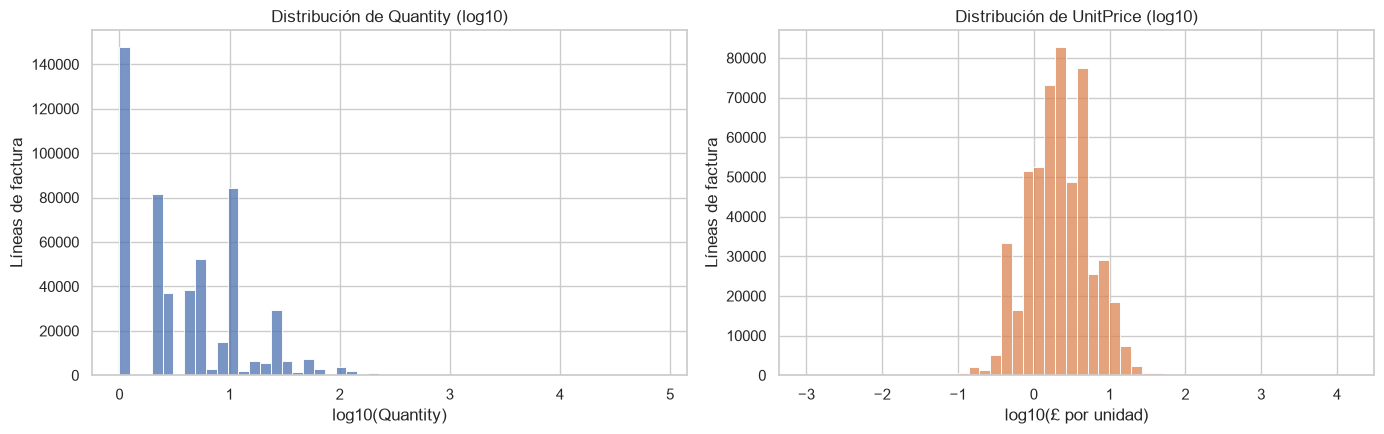

In [8]:
eda = df_raw.copy()
eda["InvoiceDate"] = pd.to_datetime(eda["InvoiceDate"])
eda["Total"] = eda["Quantity"] * eda["UnitPrice"]
ventas_eda = eda[(eda["Quantity"] > 0) & (eda["UnitPrice"] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# 1) Distribución de cantidad y precio (escala log): muestra el fuerte sesgo
sns.histplot(np.log10(ventas_eda["Quantity"]), bins=50, ax=axes[0], color="#4C72B0")
axes[0].set(title="Distribución de Quantity (log10)", xlabel="log10(Quantity)", ylabel="Líneas de factura")
sns.histplot(np.log10(ventas_eda["UnitPrice"]), bins=50, ax=axes[1], color="#DD8452")
axes[1].set(title="Distribución de UnitPrice (log10)", xlabel="log10(£ por unidad)", ylabel="Líneas de factura")
plt.tight_layout(); guardar(fig, "eda_1_distribuciones"); plt.show()

Reino Unido concentra el 84.6% de los ingresos


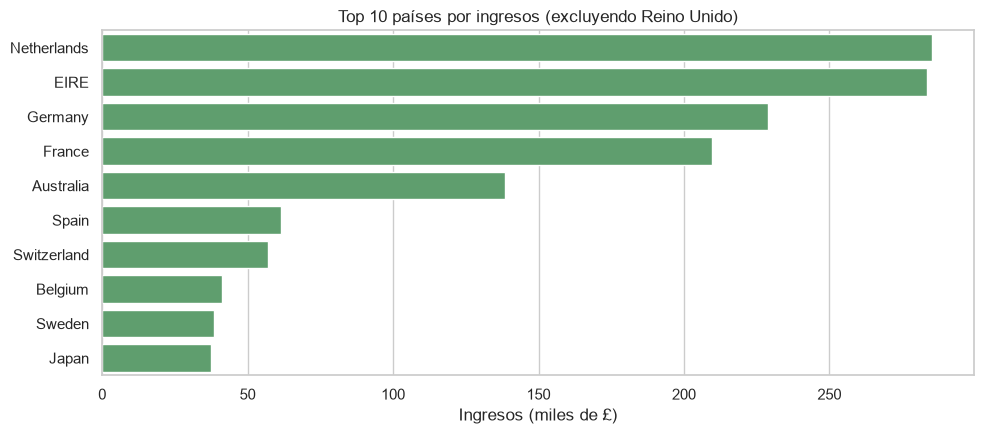

In [9]:
# 2) Top 10 países por ingresos (sin Reino Unido para poder comparar el resto)
pais = ventas_eda.groupby("Country")["Total"].sum().sort_values(ascending=False)
print(f"Reino Unido concentra el {pais.iloc[0] / pais.sum():.1%} de los ingresos")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=pais.iloc[1:11].values / 1e3, y=pais.iloc[1:11].index, ax=ax, color="#55A868")
ax.set(title="Top 10 países por ingresos (excluyendo Reino Unido)", xlabel="Ingresos (miles de £)", ylabel="")
plt.tight_layout(); guardar(fig, "eda_2_paises"); plt.show()

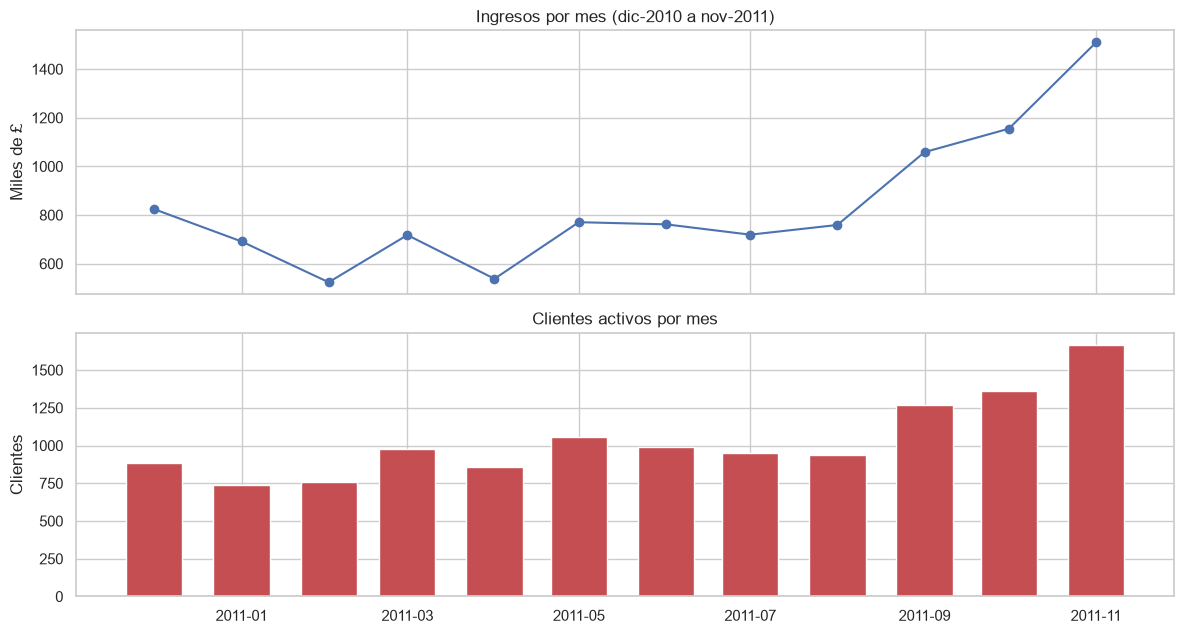

In [10]:
# 3) Evolución mensual de ingresos y clientes activos
mensual = ventas_eda.set_index("InvoiceDate").resample("MS").agg({"Total": "sum", "CustomerID": "nunique"})
mensual = mensual.iloc[:-1]  # diciembre 2011 está incompleto (solo 9 días)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax1.plot(mensual.index, mensual["Total"] / 1e3, marker="o", color="#4C72B0")
ax1.set(title="Ingresos por mes (dic-2010 a nov-2011)", ylabel="Miles de £")
ax2.bar(mensual.index, mensual["CustomerID"], width=20, color="#C44E52")
ax2.set(title="Clientes activos por mes", ylabel="Clientes")
plt.tight_layout(); guardar(fig, "eda_3_mensual"); plt.show()

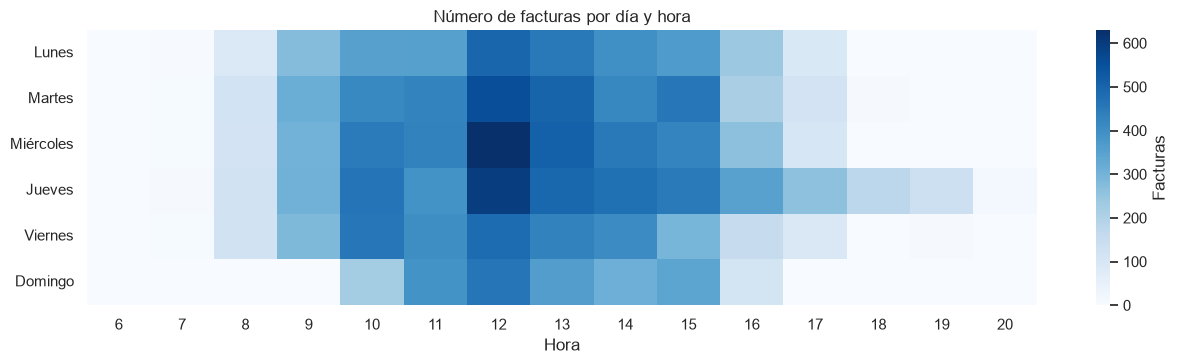

In [11]:
# 4) Mapa de calor: día de la semana vs hora de compra
dias = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
tabla = (ventas_eda.assign(dia=ventas_eda["InvoiceDate"].dt.dayofweek, hora=ventas_eda["InvoiceDate"].dt.hour)
         .pivot_table(index="dia", columns="hora", values="InvoiceNo", aggfunc="nunique", fill_value=0))
tabla.index = [dias[i] for i in tabla.index]
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(tabla, cmap="Blues", ax=ax, cbar_kws={"label": "Facturas"})
ax.set(title="Número de facturas por día y hora", xlabel="Hora", ylabel="")
plt.tight_layout(); guardar(fig, "eda_4_dia_hora"); plt.show()

**Hallazgos de la exploración**
1. Las cantidades y precios están extremadamente sesgados: la mayoría de las líneas son de pocas unidades y
   precios bajos, pero existen pedidos mayoristas enormes. Esto anticipa la necesidad de **transformar
   (logaritmo) y escalar** antes de aplicar K-Means.
2. Reino Unido concentra la gran mayoría de los ingresos; Países Bajos, Irlanda (EIRE), Alemania y Francia son
   los principales mercados extranjeros.
3. Las ventas crecen fuertemente de septiembre a noviembre (temporada navideña), y el número de clientes
   activos sigue la misma tendencia.
4. La tienda no registra ventas en sábado, y la actividad se concentra entre las 10:00 y las 15:00: un patrón
   típico de **clientes empresariales**.

### 2.8 Selección de variables para el agrupamiento
El dataset es **transaccional** (una fila por producto vendido), pero queremos segmentar **clientes**. Por eso
se construye una tabla con una fila por cliente y se usan las tres variables del modelo RFM:

| Variable | Cálculo | Justificación |
|---|---|---|
| **Recencia** | Días desde la última compra hasta el 10/12/2011 | Mide qué tan "activo" sigue el cliente. Es el mejor indicador de riesgo de abandono. |
| **Frecuencia** | Número de facturas distintas | Mide la lealtad y el hábito de compra. |
| **Monetario** | Gasto neto total (ventas − devoluciones), en £ | Mide el valor económico del cliente para el negocio. |

Estas tres variables son numéricas continuas, tienen significado de negocio directo y capturan dimensiones
distintas del comportamiento (cuándo, cuántas veces y cuánto). Se calculan además variables complementarias
(**ticket promedio, productos distintos, antigüedad, tasa de devolución, país y región**) que no entran al
modelo, pero sirven para describir los segmentos y filtrar el dashboard.

## Parte 3. Limpieza y preparación de datos

Se documenta cada paso con el número de registros antes y después para que el proceso sea trazable.

In [12]:
bitacora = []
def registrar(paso, antes, despues):
    bitacora.append({"Paso": paso, "Antes": antes, "Después": despues, "Eliminados": antes - despues})

df = df_raw.copy()
n0 = len(df)

### 3.1 Corrección de tipos de datos
* `InvoiceDate` → `datetime64`
* `CustomerID` → entero (tras eliminar los nulos, ver 3.3)

In [13]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print(df.dtypes)

InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


### 3.2 Registros duplicados

In [14]:
antes = len(df)
df = df.drop_duplicates()
registrar("Eliminar filas duplicadas", antes, len(df))
print(f"Duplicados eliminados: {antes - len(df):,}")

Duplicados eliminados: 5,268


### 3.3 Valores nulos
* **`CustomerID` nulo:** se eliminan esos registros. No es posible imputar a qué cliente pertenecen y el
  objetivo es segmentar clientes; imputar un identificador inventado crearía un "cliente" ficticio enorme.
* **`Description` nula:** se revisa cuántas quedan después de eliminar los `CustomerID` nulos.

In [15]:
antes = len(df)
df = df.dropna(subset=["CustomerID"])
registrar("Eliminar registros sin CustomerID", antes, len(df))
df["CustomerID"] = df["CustomerID"].astype(int)
print(f"Registros sin CustomerID eliminados: {antes - len(df):,}")
print(f"Descripciones nulas restantes: {df['Description'].isna().sum()}")
print(df.isna().sum())

Registros sin CustomerID eliminados: 135,037
Descripciones nulas restantes: 0
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


Todas las descripciones nulas pertenecían a registros sin cliente, por lo que ya no quedan valores nulos.

### 3.4 Inconsistencias en los datos
Se detectaron y corrigieron las siguientes inconsistencias:

1. **Códigos de producto en mayúsculas/minúsculas mezcladas** (`m` y `M`) y espacios sobrantes en textos.
2. **Un mismo `StockCode` con varias descripciones distintas** (p. ej. errores tipográficos). Se unifica con la
   descripción más frecuente de cada código.
3. **Códigos que no son productos**: gastos de envío (`POST`, `DOT`), ajustes manuales (`M`), descuentos (`D`),
   comisiones (`BANK CHARGES`, `AMAZONFEE`), muestras (`S`), etc. No reflejan comportamiento de compra.
4. **Nombres de país no estandarizados**: `EIRE` → `Ireland`, `RSA` → `South Africa`; `Unspecified` y
   `European Community` se agrupan como no especificados.
5. **Clientes con más de un país registrado**: se les asigna su país más frecuente.
6. **Precios iguales a 0**: líneas de regalo o error de captura; se excluyen de las ventas.

In [16]:
# 1) Normalizar textos
df["StockCode"] = df["StockCode"].str.strip().str.upper()
df["Description"] = df["Description"].str.strip().str.upper()
df["Country"] = df["Country"].str.strip()

# 2) Unificar descripciones por StockCode
desc_por_codigo = df.groupby("StockCode")["Description"].nunique()
print(f"StockCodes con más de una descripción: {(desc_por_codigo > 1).sum()}")
desc_moda = df.groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])
df["Description"] = df["StockCode"].map(desc_moda)

# 3) Eliminar códigos que no son productos
NO_PRODUCTOS = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS", "B"]
print("\nLíneas con códigos que no son productos:")
print(df.loc[df["StockCode"].isin(NO_PRODUCTOS), "StockCode"].value_counts())
antes = len(df)
df = df[~df["StockCode"].isin(NO_PRODUCTOS)]
registrar("Eliminar códigos que no son productos", antes, len(df))

# 4) Estandarizar países
df["Country"] = df["Country"].replace({"EIRE": "Ireland", "RSA": "South Africa",
                                       "Unspecified": "No especificado",
                                       "European Community": "No especificado"})

# 6) Precios iguales a 0
print(f"\nLíneas con UnitPrice = 0: {(df['UnitPrice'] == 0).sum()}")
antes = len(df)
df = df[df["UnitPrice"] > 0]
registrar("Eliminar líneas con precio 0", antes, len(df))

StockCodes con más de una descripción: 210



Líneas con códigos que no son productos:
StockCode
POST            1196
M                460
C2               134
D                 77
DOT               16
CRUK              16
BANK CHARGES      12
PADS               4
Name: count, dtype: int64

Líneas con UnitPrice = 0: 33


### 3.5 Separación de ventas y devoluciones
Las facturas que empiezan con **C** son cancelaciones (cantidad negativa). No se eliminan sin más: se separan
para **descontar las devoluciones del gasto de cada cliente** y calcular su tasa de devolución.

In [17]:
df["Total"] = df["Quantity"] * df["UnitPrice"]
es_cancelacion = df["InvoiceNo"].str.startswith("C")
ventas = df[~es_cancelacion & (df["Quantity"] > 0)].copy()
devoluciones = df[es_cancelacion].copy()
registrar("Separar devoluciones (no son ventas)", len(df), len(ventas))
print(f"Líneas de venta: {len(ventas):,} | Líneas de devolución: {len(devoluciones):,}")
print(f"Ventas brutas: £{ventas['Total'].sum():,.0f} | Devoluciones: £{-devoluciones['Total'].sum():,.0f}")

Líneas de venta: 391,150 | Líneas de devolución: 8,506
Ventas brutas: £8,737,228 | Devoluciones: £471,751


### 3.6 Construcción de la tabla de clientes (ingeniería de variables)
Fecha de referencia: **10/12/2011** (un día después de la última factura).

In [18]:
FECHA_REF = ventas["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Fecha de referencia:", FECHA_REF.date())

clientes = ventas.groupby("CustomerID").agg(
    UltimaCompra=("InvoiceDate", "max"),
    PrimeraCompra=("InvoiceDate", "min"),
    Frecuencia=("InvoiceNo", "nunique"),
    Ventas=("Total", "sum"),
    Productos=("StockCode", "nunique"),
    Unidades=("Quantity", "sum"),
)
clientes["Recencia"] = (FECHA_REF - clientes["UltimaCompra"]).dt.days
clientes["Antiguedad"] = (FECHA_REF - clientes["PrimeraCompra"]).dt.days
clientes["Devoluciones"] = (-devoluciones.groupby("CustomerID")["Total"].sum()).reindex(clientes.index).fillna(0)
# Se redondea a centavos: sin esto, restas como 77183.60 - 77183.60 dejan residuos de punto flotante (1e-12)
clientes["Monetario"] = (clientes["Ventas"] - clientes["Devoluciones"]).round(2)
clientes["TicketPromedio"] = clientes["Ventas"] / clientes["Frecuencia"]
clientes["TasaDevolucion"] = (clientes["Devoluciones"] / clientes["Ventas"]).clip(0, 1)

# País: el más frecuente de cada cliente (corrige clientes con varios países)
paises_por_cliente = ventas.groupby("CustomerID")["Country"].nunique()
print(f"Clientes con más de un país: {(paises_por_cliente > 1).sum()}")
clientes["Pais"] = ventas.groupby("CustomerID")["Country"].agg(lambda s: s.value_counts().index[0])

EUROPA = {"Austria", "Belgium", "Channel Islands", "Cyprus", "Czech Republic", "Denmark", "Finland", "France",
          "Germany", "Greece", "Iceland", "Ireland", "Italy", "Lithuania", "Malta", "Netherlands", "Norway",
          "Poland", "Portugal", "Spain", "Sweden", "Switzerland"}
clientes["Region"] = np.select(
    [clientes["Pais"] == "United Kingdom", clientes["Pais"].isin(EUROPA)],
    ["Reino Unido", "Europa"], default="Resto del mundo")

clientes = clientes.drop(columns=["UltimaCompra", "PrimeraCompra"])
print(f"Clientes: {len(clientes):,}")
clientes.head(10)

Fecha de referencia: 2011-12-10


Clientes con más de un país: 8


Clientes: 4,334


,Frecuencia,Ventas,Productos,Unidades,Recencia,Antiguedad,Devoluciones,Monetario,TicketPromedio,TasaDevolucion,Pais,Region
CustomerID,,,,,,,,,,,,
12346,1,"77,183.60",1,74215,325,325,"77,183.60",0.00,"77,183.60",1.00,United Kingdom,Reino Unido
12347,7,"4,310.00",103,2458,2,367,0.00,"4,310.00",615.71,0.00,Iceland,Europa
12348,4,"1,437.24",21,2332,75,358,0.00,"1,437.24",359.31,0.00,Finland,Europa
12349,1,"1,457.55",72,630,18,18,0.00,"1,457.55","1,457.55",0.00,Italy,Europa
12350,1,294.40,16,196,310,310,0.00,294.40,294.40,0.00,Norway,Europa
12352,7,"1,385.74",57,526,36,296,120.33,"1,265.41",197.96,0.09,Norway,Europa
12353,1,89.00,4,20,204,204,0.00,89.00,89.00,0.00,Bahrain,Resto del mundo
12354,1,"1,079.40",58,530,232,232,0.00,"1,079.40","1,079.40",0.00,Spain,Europa
12355,1,459.40,13,240,214,214,0.00,459.40,459.40,0.00,Bahrain,Resto del mundo


### 3.7 Clientes con gasto neto no positivo
Algunos clientes devolvieron todo (o más de) lo que compraron en el periodo. El caso más llamativo es el cliente
12346, que compró 74,215 unidades por £77,183 y canceló el pedido el mismo día. Con gasto neto ≤ 0 no
representan un comportamiento de compra real, por lo que se excluyen.

In [19]:
print(clientes[clientes["Monetario"] <= 0][["Frecuencia", "Ventas", "Devoluciones", "Monetario"]])
antes = len(clientes)
clientes = clientes[clientes["Monetario"] > 0].copy()
print(f"\nClientes eliminados: {antes - len(clientes)} | Clientes finales: {len(clientes):,}")

            Frecuencia    Ventas  Devoluciones  Monetario
CustomerID                                               
12346                1 77,183.60     77,183.60       0.00
12454                1  3,528.34      3,528.34       0.00
12558                1    269.96        269.96       0.00
12607                1  1,579.51      1,579.51       0.00
13364                1    134.96        134.96       0.00
13672                2    186.39        186.39       0.00
13762                1    306.72        306.72       0.00
14557                1    788.38        788.38       0.00
14792                1      6.20          6.20       0.00
16546                2    787.15        883.08     -95.93
16878                1     13.30         13.30       0.00
17548                1    103.30        244.78    -141.48
18268                1     25.50         25.50       0.00
18274                1    175.92        175.92       0.00

Clientes eliminados: 14 | Clientes finales: 4,320


### 3.8 Valores atípicos
Se identifican con el criterio del **rango intercuartílico (IQR)**: un valor es atípico si está por encima de
Q3 + 1.5·IQR o por debajo de Q1 − 1.5·IQR.

In [20]:
VARS_RFM = ["Recencia", "Frecuencia", "Monetario"]

def resumen_atipicos(data, columnas):
    filas = []
    for c in columnas:
        q1, q3 = data[c].quantile([.25, .75]); iqr = q3 - q1
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = ((data[c] < lim_inf) | (data[c] > lim_sup)).sum()
        filas.append({"Variable": c, "Q1": q1, "Q3": q3, "Límite superior": lim_sup,
                      "Máximo": data[c].max(), "Atípicos": n, "% atípicos": n / len(data) * 100})
    return pd.DataFrame(filas).set_index("Variable")

resumen_atipicos(clientes, VARS_RFM + ["TicketPromedio", "Productos"])

,Q1,Q3,Límite superior,Máximo,Atípicos,% atípicos
Variable,,,,,,
Recencia,17.00,142.00,329.50,373.00,153,3.54
Frecuencia,1.00,5.00,11.00,206.00,278,6.44
Monetario,299.05,"1,610.46","3,577.58","278,778.02",410,9.49
TicketPromedio,177.52,423.32,792.03,"84,236.25",290,6.71
Productos,16.00,77.25,169.12,"1,785.00",305,7.06


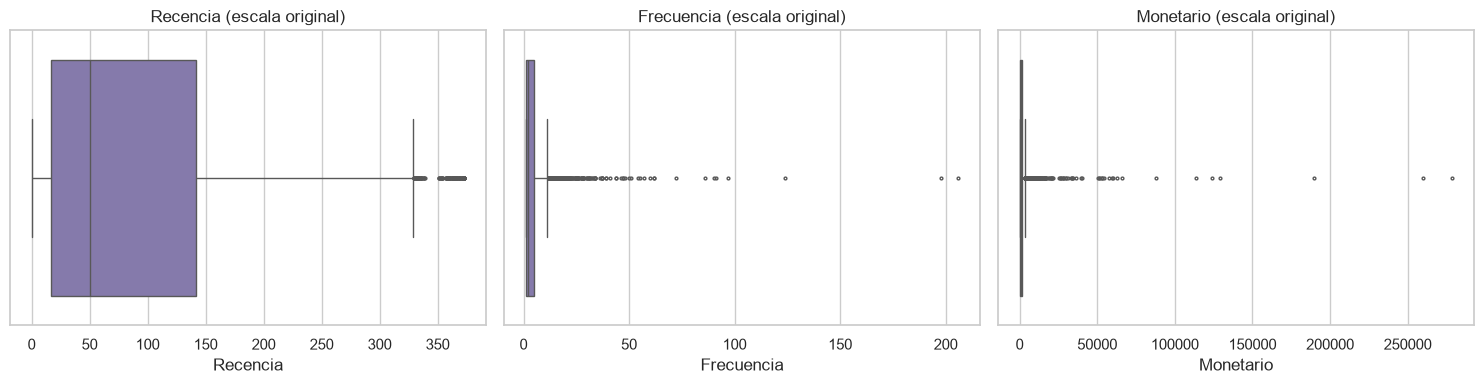

Recencia      1.25
Frecuencia   11.94
Monetario    21.54
Name: Asimetría (skew), dtype: float64


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, VARS_RFM):
    sns.boxplot(x=clientes[c], ax=ax, color="#8172B3", fliersize=2)
    ax.set_title(f"{c} (escala original)")
plt.tight_layout(); guardar(fig, "prep_1_boxplots_originales"); plt.show()
print(clientes[VARS_RFM].skew().rename("Asimetría (skew)"))

**Tratamiento de los atípicos: se conservan y se transforman con logaritmo.**

* En Frecuencia y Monetario, entre 6% y 10% de los clientes son atípicos según el IQR. **No son errores**: son los
  clientes mayoristas que más compran (el mayor gastó cerca de £280,000). Eliminarlos borraría justamente al
  segmento más valioso para el negocio.
* Sin embargo, K-Means usa distancias euclidianas y calcula medias, así que unos pocos valores extremos
  "arrastran" los centroides y crean clústeres de 1-6 clientes (se demuestra en la Parte 4.7).
* **Solución:** aplicar `log1p(x) = ln(1 + x)`, que comprime los valores grandes y conserva el orden. La
  asimetría de Frecuencia baja de ~12 a ~1.2 y la de Monetario de ~22 a ~0.4.
* Los errores evidentes (gasto neto ≤ 0, precios 0, pedidos cancelados) ya se eliminaron en los pasos anteriores.

### 3.9 Transformación logarítmica y codificación

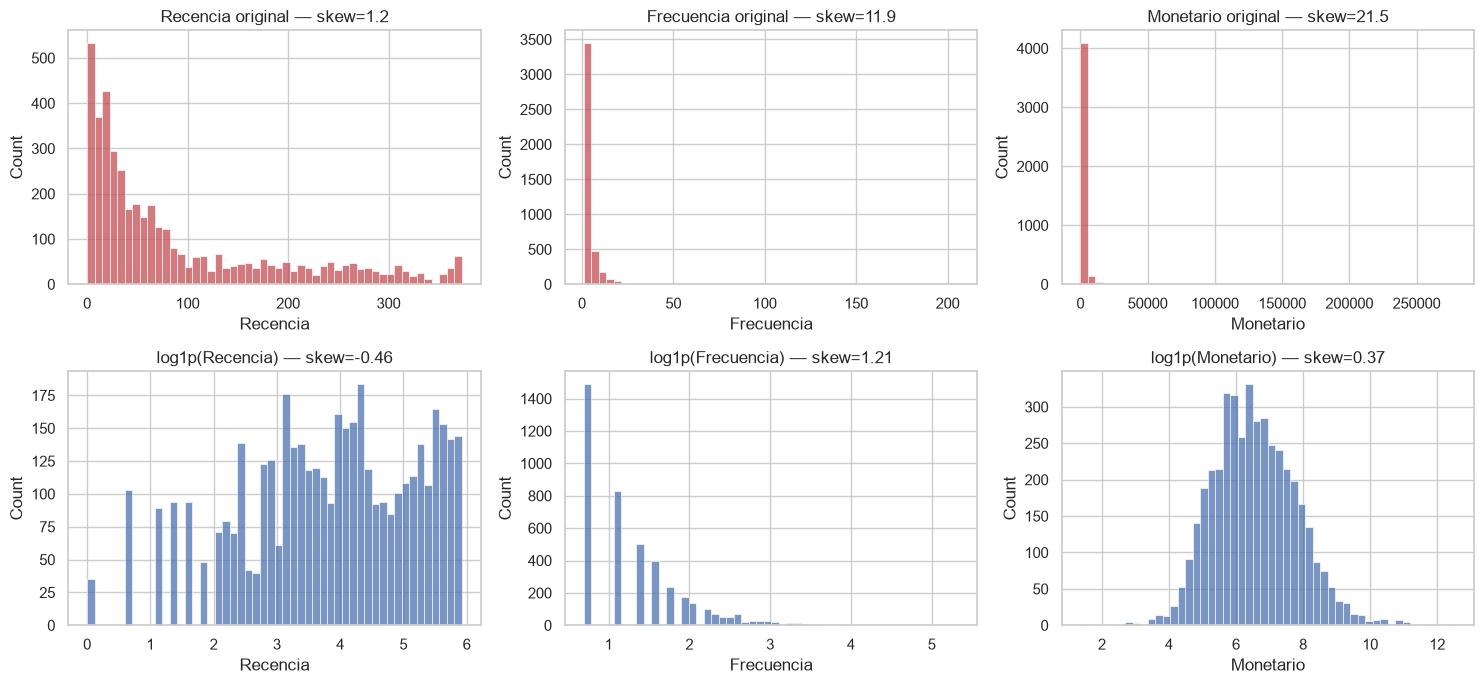

In [22]:
X_log = np.log1p(clientes[VARS_RFM])
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(VARS_RFM):
    sns.histplot(clientes[c], bins=50, ax=axes[0, i], color="#C44E52")
    axes[0, i].set_title(f"{c} original — skew={clientes[c].skew():.1f}")
    sns.histplot(X_log[c], bins=50, ax=axes[1, i], color="#4C72B0")
    axes[1, i].set_title(f"log1p({c}) — skew={X_log[c].skew():.2f}")
plt.tight_layout(); guardar(fig, "prep_2_transformacion_log"); plt.show()

**Codificación de variables categóricas.** K-Means trabaja con distancias euclidianas, por lo que **no se
incluyen `Pais` ni `Region` en el modelo**: una variable categórica codificada con *one-hot* dominaría las
distancias (un 0/1 pesa igual que varias desviaciones estándar) y segmentaría por país en lugar de por
comportamiento. Aun así se codifica la región con *one-hot* para el análisis posterior por segmento.

In [23]:
region_dummies = pd.get_dummies(clientes["Region"], prefix="Region", dtype=int)
clientes = clientes.join(region_dummies)
clientes[["Pais", "Region"] + list(region_dummies.columns)].head()

,Pais,Region,Region_Europa,Region_Reino Unido,Region_Resto del mundo
CustomerID,,,,,
12347,Iceland,Europa,1,0,0
12348,Finland,Europa,1,0,0
12349,Italy,Europa,1,0,0
12350,Norway,Europa,1,0,0
12352,Norway,Europa,1,0,0


### 3.10 Escalamiento con `StandardScaler`
Aun después del logaritmo, las variables tienen rangos distintos (Recencia ≈ 0-6, Monetario ≈ 1-13). K-Means
daría más peso a la variable con mayor rango. `StandardScaler` deja cada variable con **media 0 y desviación
estándar 1**: z = (x − μ) / σ.

In [24]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
X_scaled_df = pd.DataFrame(X_scaled, columns=VARS_RFM, index=clientes.index)

comparacion = pd.concat({
    "Original": clientes[VARS_RFM].agg(["mean", "std", "min", "max"]),
    "Log": X_log.agg(["mean", "std", "min", "max"]),
    "Log + StandardScaler": X_scaled_df.agg(["mean", "std", "min", "max"]),
}, axis=1).round(2)
comparacion

Original                            Log                      Log + StandardScaler                     
     Recencia Frecuencia  Monetario Recencia Frecuencia Monetario             Recencia Frecuencia Monetario
mean    92.07       4.26   1,914.27     3.80       1.34      6.56                 0.00       0.00     -0.00
std    100.12       7.65   8,303.78     1.38       0.68      1.25                 1.00       1.00      1.00
min      0.00       1.00       2.90     0.00       0.69      1.36                -2.75      -0.95     -4.16
max    373.00     206.00 278,778.02     5.92       5.33     12.54                 1.53       5.85      4.79

### 3.11 Resultados de la limpieza y preparación

In [25]:
bitacora_df = pd.DataFrame(bitacora)
print(bitacora_df.to_string(index=False))
print(f"\nRegistros originales: {n0:,} -> líneas de venta válidas: {len(ventas):,} "
      f"({len(ventas)/n0:.1%})")
print(f"Tabla final para el modelo: {X_scaled.shape[0]:,} clientes x {X_scaled.shape[1]} variables")

                                 Paso  Antes  Después  Eliminados
            Eliminar filas duplicadas 541909   536641        5268
    Eliminar registros sin CustomerID 536641   401604      135037
Eliminar códigos que no son productos 401604   399689        1915
         Eliminar líneas con precio 0 399689   399656          33
 Separar devoluciones (no son ventas) 399656   391150        8506

Registros originales: 541,909 -> líneas de venta válidas: 391,150 (72.2%)
Tabla final para el modelo: 4,320 clientes x 3 variables


**Importancia de las transformaciones realizadas**
* **Limpieza (duplicados, nulos, códigos no producto, precios 0):** sin ella, los envíos, comisiones y
  registros repetidos inflarían el gasto y la frecuencia de algunos clientes.
* **Separar devoluciones:** el valor real de un cliente es lo que compra menos lo que devuelve.
* **Agregar por cliente:** convierte 390 mil líneas de factura en ~4,300 perfiles comparables, que es la unidad
  de análisis del problema.
* **Logaritmo:** reduce la asimetría para que K-Means no forme clústeres de uno o dos clientes extremos.
* **StandardScaler:** iguala la escala para que las tres variables pesen lo mismo en la distancia.

## Parte 4. Implementación del algoritmo K-Means

### 4.1 Variables del modelo
Se entrena con **3 variables**: `Recencia`, `Frecuencia` y `Monetario`, transformadas con `log1p` y escaladas
con `StandardScaler` (matriz `X_scaled`).

### 4.2 Evaluación de distintos valores de K (de 2 a 10)
Se calculan cuatro métricas:
* **Inercia (WCSS):** suma de distancias al cuadrado al centroide; se busca el "codo".
* **Silueta:** de −1 a 1; mientras más alta, mejor separados están los grupos.
* **Davies-Bouldin:** mientras más bajo, mejor.
* **Calinski-Harabasz:** mientras más alto, mejor.

In [26]:
resultados = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    etiquetas = km.fit_predict(X_scaled)
    resultados.append({"K": k, "Inercia": km.inertia_,
                       "Silueta": silhouette_score(X_scaled, etiquetas),
                       "Davies-Bouldin": davies_bouldin_score(X_scaled, etiquetas),
                       "Calinski-Harabasz": calinski_harabasz_score(X_scaled, etiquetas),
                       "Tamaño mínimo": np.bincount(etiquetas).min()})
evaluacion = pd.DataFrame(resultados).set_index("K")
evaluacion["Reducción inercia %"] = (-evaluacion["Inercia"].pct_change() * 100)
evaluacion.round(3)

,Inercia,Silueta,Davies-Bouldin,Calinski-Harabasz,Tamaño mínimo,Reducción inercia %
K,,,,,,
2,"6,459.06",0.43,0.89,"4,346.00",1651,NaN
3,"4,849.43",0.34,1.04,"3,610.05",735,24.92
4,"3,933.95",0.34,1.01,"3,300.92",685,18.88
5,"3,308.35",0.32,0.99,"3,147.12",269,15.90
6,"2,855.43",0.31,1.01,"3,053.25",314,13.69
7,"2,557.06",0.31,0.98,"2,924.47",211,10.45
8,"2,344.34",0.29,1.01,"2,789.38",177,8.32
9,"2,162.37",0.28,1.02,"2,690.88",208,7.76
10,"2,004.58",0.28,1.02,"2,617.24",150,7.30


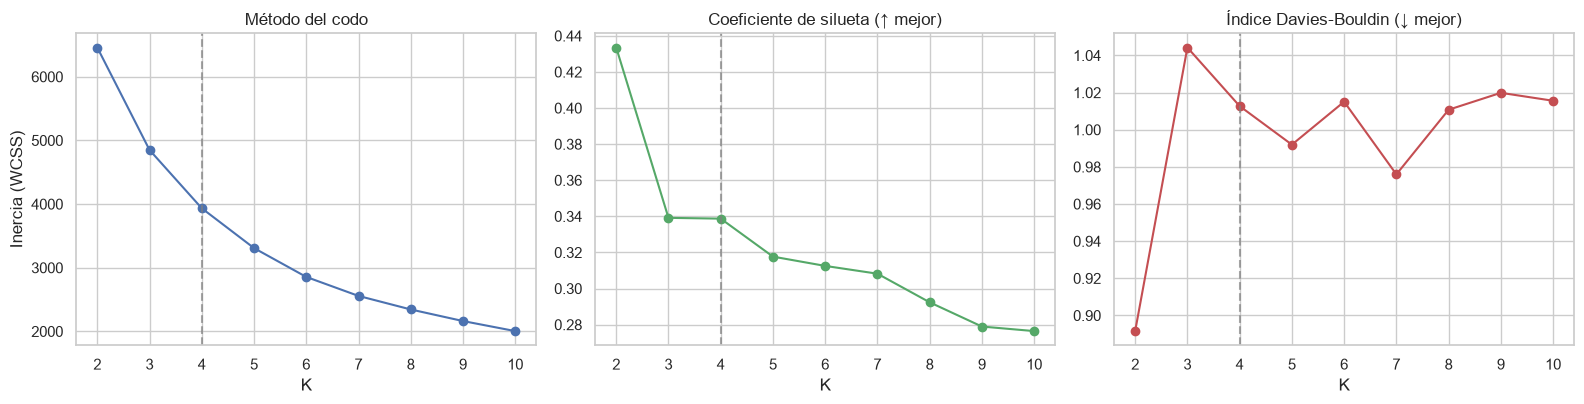

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(evaluacion.index, evaluacion["Inercia"], "o-", color="#4C72B0")
axes[0].set(title="Método del codo", xlabel="K", ylabel="Inercia (WCSS)")
axes[1].plot(evaluacion.index, evaluacion["Silueta"], "o-", color="#55A868")
axes[1].set(title="Coeficiente de silueta (↑ mejor)", xlabel="K")
axes[2].plot(evaluacion.index, evaluacion["Davies-Bouldin"], "o-", color="#C44E52")
axes[2].set(title="Índice Davies-Bouldin (↓ mejor)", xlabel="K")
for ax in axes:
    ax.axvline(4, ls="--", color="gray", alpha=.7)
plt.tight_layout(); guardar(fig, "kmeans_1_seleccion_k"); plt.show()

### 4.3 Selección y justificación de K = 4
* **Codo:** la inercia baja mucho de K=2 a K=4 (−25% y −19%); a partir de K=5 cada clúster extra aporta menos
  (−16%, −14%, −10%...). El codo se ubica en **K = 4**.
* **Silueta:** K=2 tiene la silueta más alta (0.43), pero solo separa "buenos" y "malos" clientes, algo que no
  aporta decisiones nuevas. Entre K=3 y K=4 la silueta es prácticamente igual (≈0.34), y luego desciende.
* **Davies-Bouldin:** K=4 es mejor que K=3 (1.01 vs 1.04).
* **Utilidad de negocio:** cuatro segmentos son suficientes para diseñar acciones distintas y pocos para que el
  área comercial los gestione. K=5 divide a los mejores clientes en dos grupos parecidos.

Se elige **K = 4**. La silueta (~0.34) indica una estructura moderada: es habitual en datos de clientes,
donde el comportamiento cambia de forma gradual y no en grupos perfectamente separados.

### 4.4 Entrenamiento del modelo final y asignación con `fit_predict()`

In [28]:
K_OPTIMO = 4
kmeans = KMeans(n_clusters=K_OPTIMO, init="k-means++", n_init=10, max_iter=300, random_state=RANDOM_STATE)
clientes["Cluster"] = kmeans.fit_predict(X_scaled)

print(f"Iteraciones hasta converger: {kmeans.n_iter_}")
print(f"Inercia: {kmeans.inertia_:,.1f}")
print(f"Silueta: {silhouette_score(X_scaled, clientes['Cluster']):.3f}")
clientes[VARS_RFM + ["Cluster"]].head(10)

Iteraciones hasta converger: 26
Inercia: 3,933.9


Silueta: 0.339


,Recencia,Frecuencia,Monetario,Cluster
CustomerID,,,,
12347,2,7,"4,310.00",2
12348,75,4,"1,437.24",0
12349,18,1,"1,457.55",3
12350,310,1,294.40,1
12352,36,7,"1,265.41",0
12353,204,1,89.00,1
12354,232,1,"1,079.40",1
12355,214,1,459.40,1
12356,22,3,"2,487.43",0


### 4.5 Centroides

In [29]:
centroides_esc = pd.DataFrame(kmeans.cluster_centers_, columns=VARS_RFM)
centroides_esc.index.name = "Cluster"
# Volver a unidades originales: deshacer el escalamiento y el logaritmo
centroides_orig = pd.DataFrame(np.expm1(scaler.inverse_transform(kmeans.cluster_centers_)),
                               columns=VARS_RFM).round(1)
centroides_orig.index.name = "Cluster"
print("Centroides en unidades estandarizadas (z):")
display(centroides_esc.round(2))
print("Centroides en unidades originales (días, compras, £):")
display(centroides_orig)

Centroides en unidades estandarizadas (z):


,Recencia,Frecuencia,Monetario
Cluster,,,
0,0.12,0.33,0.53
1,0.87,-0.77,-0.79
2,-1.27,1.69,1.43
3,-0.87,-0.36,-0.39


Centroides en unidades originales (días, compras, £):


,Recencia,Frecuencia,Monetario
Cluster,,,
0,51.90,3.80,"1,359.20"
1,148.00,1.30,261.10
2,6.70,11.20,"4,190.10"
3,12.40,2.00,431.90


**Interpretación de los centroides.** En la escala estandarizada, un valor positivo significa "por encima del
cliente promedio" y uno negativo "por debajo". Al regresar a unidades originales (deshaciendo escala y
logaritmo) el centroide equivale aproximadamente a la **media geométrica** del grupo, que es más cercana a la
mediana que a la media aritmética. La interpretación detallada de cada centroide está en la Parte 5.

### 4.6 Cantidad de registros por clúster y visualización

In [30]:
conteo = clientes["Cluster"].value_counts().sort_index().to_frame("Clientes")
conteo["%"] = (conteo["Clientes"] / conteo["Clientes"].sum() * 100).round(1)
conteo

,Clientes,%
Cluster,,
0,1192,27.60
1,1640,38.00
2,685,15.90
3,803,18.60


Varianza explicada por PC1+PC2: 93.9%


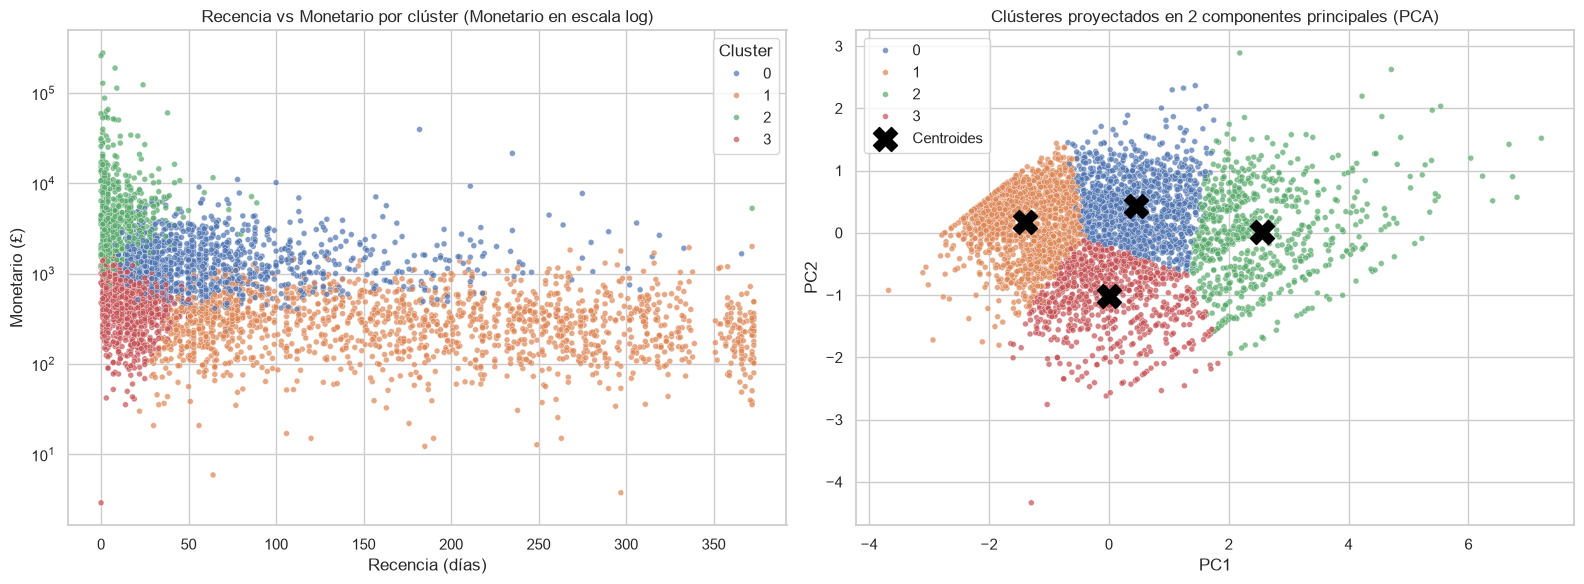

In [31]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
clientes["PC1"], clientes["PC2"] = coords[:, 0], coords[:, 1]
print(f"Varianza explicada por PC1+PC2: {pca.explained_variance_ratio_.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=clientes, x="Recencia", y="Monetario", hue="Cluster", palette="deep",
                s=18, alpha=.7, ax=axes[0])
axes[0].set(yscale="log", title="Recencia vs Monetario por clúster (Monetario en escala log)",
            xlabel="Recencia (días)", ylabel="Monetario (£)")
sns.scatterplot(data=clientes, x="PC1", y="PC2", hue="Cluster", palette="deep", s=18, alpha=.7, ax=axes[1])
cent_pca = pca.transform(kmeans.cluster_centers_)
axes[1].scatter(cent_pca[:, 0], cent_pca[:, 1], marker="X", s=300, c="black", label="Centroides")
axes[1].set_title("Clústeres proyectados en 2 componentes principales (PCA)")
axes[1].legend()
plt.tight_layout(); guardar(fig, "kmeans_2_clusters"); plt.show()

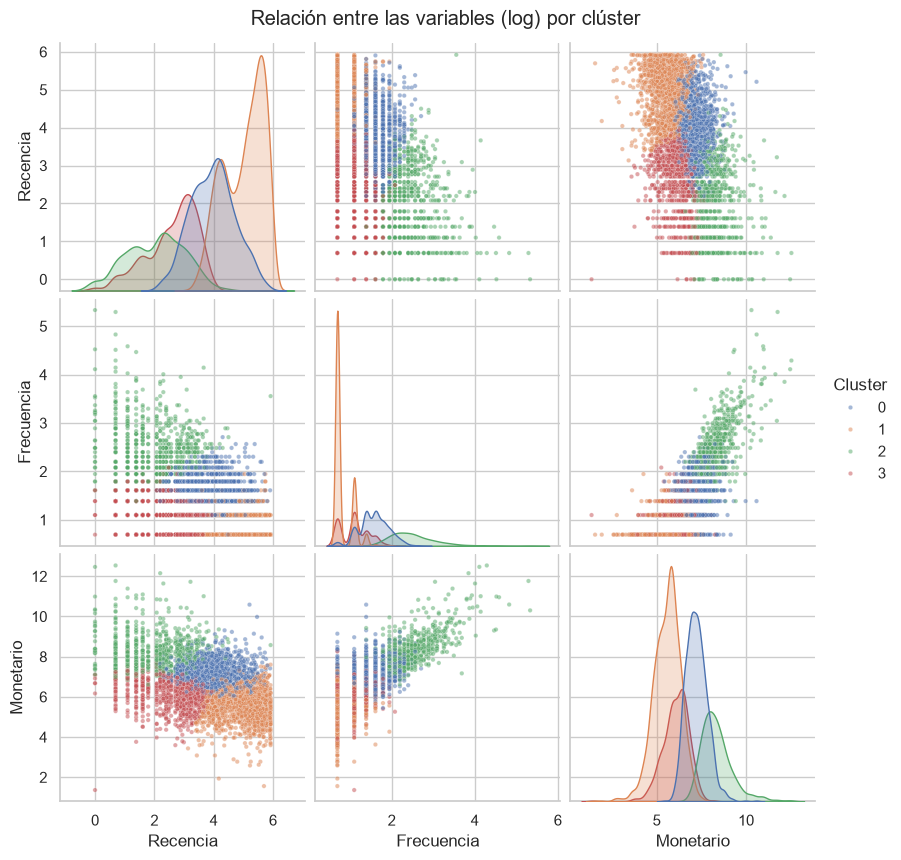

In [32]:
g = sns.pairplot(pd.concat([X_log, clientes["Cluster"]], axis=1), hue="Cluster", palette="deep",
                 plot_kws={"s": 10, "alpha": .5}, diag_kind="kde", height=2.8)
g.figure.suptitle("Relación entre las variables (log) por clúster", y=1.02)
guardar(g.figure, "kmeans_3_pairplot"); plt.show()

### 4.7 Comparación de dos configuraciones del modelo
| | Configuración A (elegida) | Configuración B |
|---|---|---|
| Variables | Recencia, Frecuencia, Monetario | Recencia, Frecuencia, Monetario |
| Transformación | `log1p` + `StandardScaler` | Solo `StandardScaler` (sin logaritmo) |
| K | 4 | 4 |
| Inicialización | k-means++, n_init=10 | k-means++, n_init=10 |

In [33]:
X_sin_log = StandardScaler().fit_transform(clientes[VARS_RFM])
kmeans_b = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=RANDOM_STATE)
etiquetas_b = kmeans_b.fit_predict(X_sin_log)

def perfil(etiquetas):
    return (clientes.assign(c=etiquetas).groupby("c")
            .agg(Clientes=("Recencia", "size"), Recencia=("Recencia", "median"),
                 Frecuencia=("Frecuencia", "median"), Monetario=("Monetario", "median"))
            .sort_values("Clientes", ascending=False))

print("Configuración A — log + StandardScaler")
display(perfil(clientes["Cluster"]))
print("Configuración B — solo StandardScaler")
display(perfil(etiquetas_b))

comparacion_cfg = pd.DataFrame({
    "Silueta": [silhouette_score(X_scaled, clientes["Cluster"]), silhouette_score(X_sin_log, etiquetas_b)],
    "Davies-Bouldin": [davies_bouldin_score(X_scaled, clientes["Cluster"]), davies_bouldin_score(X_sin_log, etiquetas_b)],
    "Clúster más pequeño": [np.bincount(clientes["Cluster"]).min(), np.bincount(etiquetas_b).min()],
    "Clúster más grande": [np.bincount(clientes["Cluster"]).max(), np.bincount(etiquetas_b).max()],
}, index=["A: log + escalado", "B: solo escalado"])
print(f"Coincidencia entre ambas particiones (Adjusted Rand Index): "
      f"{adjusted_rand_score(clientes['Cluster'], etiquetas_b):.3f}")
comparacion_cfg.round(3)

Configuración A — log + StandardScaler


,Clientes,Recencia,Frecuencia,Monetario
c,,,,
1,1640,173.00,1.00,288.79
0,1192,52.00,4.00,"1,312.85"
3,803,16.00,2.00,460.64
2,685,8.00,10.00,"3,622.95"


Configuración B — solo StandardScaler


,Clientes,Recencia,Frecuencia,Monetario
c,,,,
0,3137,31.00,3.00,853.39
1,1074,242.00,1.00,302.37
3,103,3.00,26.00,"12,334.07"
2,6,4.50,57.00,"159,171.89"


Coincidencia entre ambas particiones (Adjusted Rand Index): 0.095


,Silueta,Davies-Bouldin,Clúster más pequeño,Clúster más grande
A: log + escalado,0.34,1.01,685,1640
B: solo escalado,0.61,0.67,6,3137


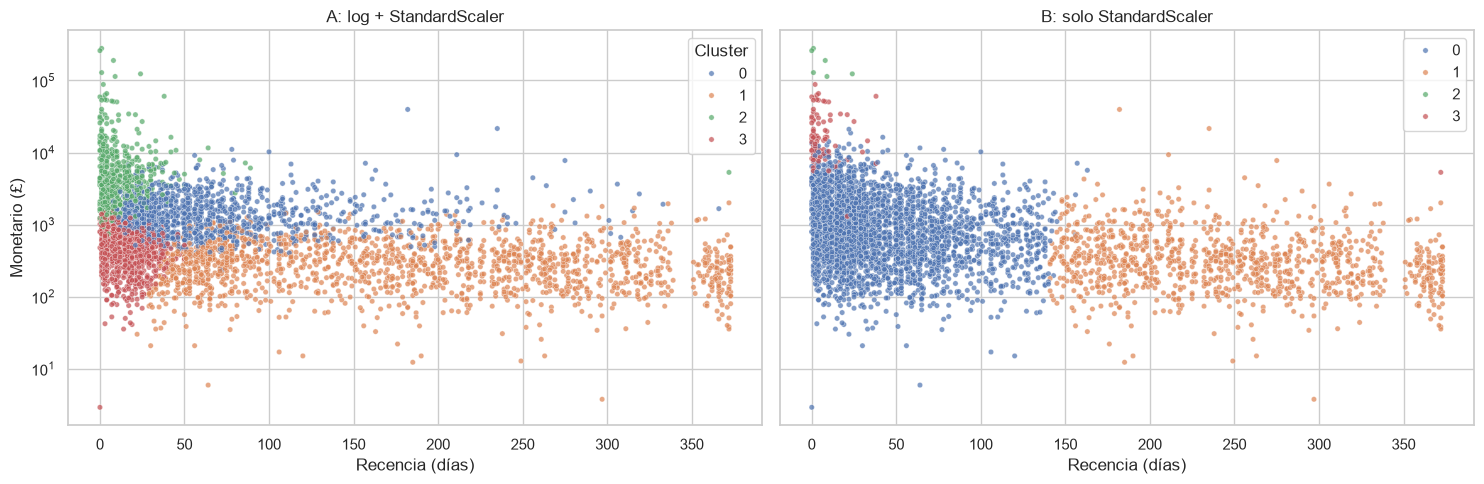

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, etq, titulo in [(axes[0], clientes["Cluster"], "A: log + StandardScaler"),
                        (axes[1], etiquetas_b, "B: solo StandardScaler")]:
    sns.scatterplot(x=clientes["Recencia"], y=clientes["Monetario"], hue=etq, palette="deep",
                    s=15, alpha=.7, ax=ax)
    ax.set(yscale="log", title=titulo, xlabel="Recencia (días)", ylabel="Monetario (£)")
plt.tight_layout(); guardar(fig, "kmeans_4_comparacion_configuraciones"); plt.show()

**Diferencias encontradas**
* La configuración **B** obtiene una silueta **más alta**, pero es engañosa: casi todos los clientes quedan en
  uno o dos grupos grandes, y los otros clústeres contienen apenas a un puñado de clientes mayoristas extremos.
  La silueta "premia" que esos pocos puntos estén muy lejos del resto, no que la segmentación sea útil.
* En B, dos de los cuatro clústeres se gastan en aislar a los clientes extremos (6 megaclientes y ~100 grandes
  compradores): los valores atípicos de Frecuencia y Monetario dominan la distancia euclidiana. Los otros
  ~4,200 clientes quedan divididos solo en "activos" e "inactivos", sin distinguir nuevos de leales.
* La configuración **A** produce cuatro grupos de tamaño razonable y con perfiles claramente diferentes en
  las tres dimensiones, que es lo que necesita el negocio.
* El *Adjusted Rand Index* bajo confirma que las dos configuraciones generan particiones muy diferentes.

**Conclusión:** el preprocesamiento (logaritmo) cambia por completo el resultado de K-Means. Una métrica
aislada (silueta) no basta para elegir el modelo; hay que revisar el tamaño y la interpretación de los grupos.

## Parte 5. Análisis e interpretación de resultados

### 5.1 Asignación de nombres a los clústeres
Los números de clúster que asigna K-Means son arbitrarios. Para que los nombres no dependan de esa numeración,
se asignan con reglas basadas en los centroides:
* Mayor gasto monetario → **Campeones**
* Mayor recencia (más tiempo sin comprar) → **Inactivos**
* De los dos restantes, el de mayor gasto → **Leales en riesgo**; el otro → **Nuevos / ocasionales**

In [35]:
c = centroides_orig.copy()
nombres = {}
nombres[c["Monetario"].idxmax()] = "Campeones"
nombres[c["Recencia"].idxmax()] = "Inactivos"
restantes = c.drop(index=list(nombres)).sort_values("Monetario")
nombres[restantes.index[0]] = "Nuevos / ocasionales"
nombres[restantes.index[1]] = "Leales en riesgo"

ORDEN = ["Campeones", "Leales en riesgo", "Nuevos / ocasionales", "Inactivos"]
clientes["Segmento"] = pd.Categorical(clientes["Cluster"].map(nombres), categories=ORDEN, ordered=True)
centroides_orig["Segmento"] = centroides_orig.index.map(nombres)
centroides_orig.set_index("Segmento").loc[ORDEN]

,Recencia,Frecuencia,Monetario
Segmento,,,
Campeones,6.70,11.20,"4,190.10"
Leales en riesgo,51.90,3.80,"1,359.20"
Nuevos / ocasionales,12.40,2.00,431.90
Inactivos,148.00,1.30,261.10


### 5.2 Estadísticas descriptivas por grupo

In [36]:
VARS_DESC = ["Recencia", "Frecuencia", "Monetario", "TicketPromedio", "Productos", "Antiguedad", "TasaDevolucion"]
estad = clientes.groupby("Segmento", observed=True)[VARS_DESC].agg(["mean", "median", "std", "min", "max"])
estad.round(1)

Recencia                        Frecuencia                       Monetario                                       ...  \
                         mean median    std min  max       mean median   std min  max      mean   median       std    min        max  ...   
Segmento                                                                                                                              ...   
Campeones               11.30   8.00  18.10   0  372      14.00  10.00 15.50   3  206  7,736.30 3,623.00 19,693.80 739.70 278,778.00  ...   
Leales en riesgo        67.90  52.00  54.80   7  366       4.10   4.00  1.80   1   14  1,667.00 1,312.80  1,692.40 230.70  39,619.50  ...   
Nuevos / ocasionales    16.70  16.00  11.30   0   50       2.20   2.00  1.10   1    7    539.90   460.60    374.70   2.90   3,861.00  ...   
Inactivos              180.30 173.00 101.60  22  373       1.30   1.00  0.60   1    6    335.10   288.80    245.40   3.80   2,002.40  ...   

                     Productos                         Antiguedad                        TasaDevolucion                        
                          mean median    std min   max       mean median    std min  max           mean median  std  min  max  
Segmento                                                                                                                       
Campeones               157.00 117.00 156.20   4  1785     311.40 358.00  82.30   2  373           0.00   0.00 0.00 0.00 0.40  
Leales en riesgo         74.30  60.00  55.70   1   420     261.60 278.00  89.10  29  373           0.00   0.00 0.10 0.00 0.50  
Nuevos / ocasionales     41.80  31.00  37.80   1   312     124.70  71.00 120.10   0  373           0.00   0.00 0.10 0.00 1.00  
Inactivos                22.20  17.00  20.40   1   155     206.30 218.00 107.30  22  373           0.00   0.00 0.10 0.00 1.00  

[4 rows x 35 columns]

In [37]:
clientes.groupby("Segmento", observed=True)[VARS_RFM].describe().round(1).T

Segmento          Campeones  Leales en riesgo  Nuevos / ocasionales  Inactivos
Recencia   count     685.00          1,192.00                803.00   1,640.00
           mean       11.30             67.90                 16.70     180.30
           std        18.10             54.80                 11.30     101.60
           min         0.00              7.00                  0.00      22.00
           25%         3.00             29.80                  7.00      79.80
           50%         8.00             52.00                 16.00     173.00
           75%        15.00             85.00                 24.00     263.00
           max       372.00            366.00                 50.00     373.00
Frecuencia count     685.00          1,192.00                803.00   1,640.00
           mean       14.00              4.10                  2.20       1.30
           std        15.50              1.80                  1.10       0.60
           min         3.00              1.00                  1.00       1.00
           25%         7.00              3.00                  1.00       1.00
           50%        10.00              4.00                  2.00       1.00
           75%        15.00              5.00                  3.00       2.00
           max       206.00             14.00                  7.00       6.00
Monetario  count     685.00          1,192.00                803.00   1,640.00
           mean    7,736.30          1,667.00                539.90     335.10
           std    19,693.80          1,692.40                374.70     245.40
           min       739.70            230.70                  2.90       3.80
           25%     2,323.50            893.00                283.70     158.90
           50%     3,623.00          1,312.80                460.60     288.80
           75%     6,228.70          1,995.30                701.60     426.50
           max   278,778.00         39,619.50              3,861.00   2,002.40

### 5.3 Tabla comparativa de los grupos

In [38]:
ingreso_total = clientes["Monetario"].sum()
tabla_comp = clientes.groupby("Segmento", observed=True).agg(
    Clientes=("Monetario", "size"),
    Ingresos=("Monetario", "sum"),
    Recencia_mediana=("Recencia", "median"),
    Frecuencia_mediana=("Frecuencia", "median"),
    Monetario_mediano=("Monetario", "median"),
    Ticket_promedio=("TicketPromedio", "median"),
    Productos_medianos=("Productos", "median"),
    Antiguedad_mediana=("Antiguedad", "median"),
    Tasa_devolucion_media=("TasaDevolucion", "mean"),
    Pct_Reino_Unido=("Region_Reino Unido", "mean"),
)
tabla_comp.insert(1, "% Clientes", tabla_comp["Clientes"] / tabla_comp["Clientes"].sum() * 100)
tabla_comp.insert(3, "% Ingresos", tabla_comp["Ingresos"] / ingreso_total * 100)
tabla_comp["Tasa_devolucion_media"] *= 100
tabla_comp["Pct_Reino_Unido"] *= 100
tabla_comp.round(1)

,Clientes,% Clientes,Ingresos,% Ingresos,Recencia_mediana,Frecuencia_mediana,Monetario_mediano,Ticket_promedio,Productos_medianos,Antiguedad_mediana,Tasa_devolucion_media,Pct_Reino_Unido
Segmento,,,,,,,,,,,,
Campeones,685,15.90,"5,299,377.80",64.10,8.00,10.00,"3,623.00",365.40,117.00,358.00,2.00,89.20
Leales en riesgo,1192,27.60,"1,987,109.20",24.00,52.00,4.00,"1,312.80",356.30,60.00,278.00,1.90,89.20
Nuevos / ocasionales,803,18.60,"433,514.80",5.20,16.00,2.00,460.60,227.10,31.00,71.00,1.50,91.70
Inactivos,1640,38.00,"549,635.50",6.60,173.00,1.00,288.80,224.00,17.00,218.00,1.70,91.20


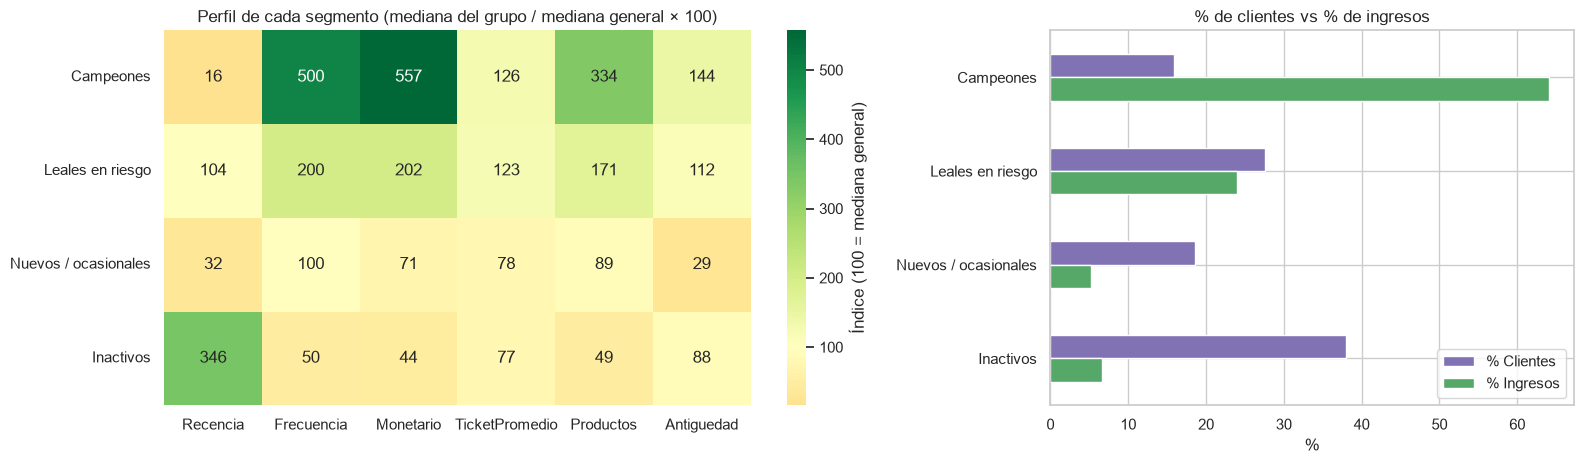

In [39]:
# Perfil relativo: cuánto se aleja cada segmento de la mediana general (índice 100 = cliente típico)
perfil_rel = (clientes.groupby("Segmento", observed=True)[VARS_DESC[:-1]].median()
              / clientes[VARS_DESC[:-1]].median() * 100)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(perfil_rel, annot=True, fmt=".0f", cmap="RdYlGn", center=100, ax=axes[0],
            cbar_kws={"label": "Índice (100 = mediana general)"})
axes[0].set(title="Perfil de cada segmento (mediana del grupo / mediana general × 100)", ylabel="")
participacion = tabla_comp[["% Clientes", "% Ingresos"]]
participacion.plot.barh(ax=axes[1], color=["#8172B3", "#55A868"])
axes[1].invert_yaxis(); axes[1].set(title="% de clientes vs % de ingresos", xlabel="%", ylabel="")
plt.tight_layout(); guardar(fig, "analisis_1_perfil_segmentos"); plt.show()

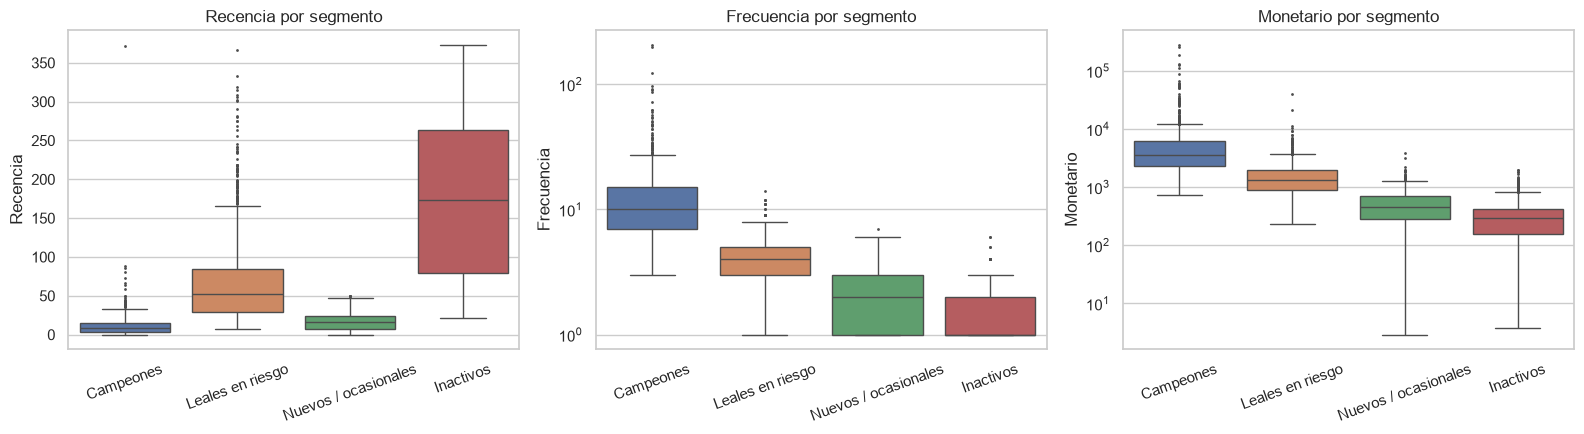

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, v in zip(axes, VARS_RFM):
    sns.boxplot(data=clientes, x="Segmento", y=v, ax=ax, palette="deep", fliersize=1)
    ax.set(yscale="log" if v != "Recencia" else "linear", title=f"{v} por segmento", xlabel="")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); guardar(fig, "analisis_2_boxplots_segmentos"); plt.show()

In [41]:
reg = pd.crosstab(clientes["Segmento"], clientes["Region"], normalize="index") * 100
reg.round(1)

Region,Europa,Reino Unido,Resto del mundo
Segmento,,,
Campeones,10.10,89.20,0.70
Leales en riesgo,9.70,89.20,1.10
Nuevos / ocasionales,8.20,91.70,0.10
Inactivos,7.60,91.20,1.30


### 5.4 Interpretación de centroides y características de cada clúster
(Los valores citados son los centroides y medianas calculados arriba.)

**🏆 Campeones** — Compraron hace muy poco (≈1 semana), lo hacen con mucha frecuencia (mediana ≈10 facturas) y
gastan varias veces más que el cliente típico. Compran una gran variedad de productos y llevan casi todo el año
como clientes. Son una minoría (~16%) pero generan la mayor parte de los ingresos.

**⚠️ Leales en riesgo** — Clientes con historial: compran unas 4 veces y gastan por encima del promedio, pero
su última compra fue hace ~2 meses. Siguen siendo valiosos, pero su recencia muestra que **se están
enfriando**: si no se actúa, pueden pasar a Inactivos.

**🌱 Nuevos / ocasionales** — Compraron recientemente (~2-3 semanas) pero solo 1-2 veces y por montos bajos.
Muchos tienen poca antigüedad: son clientes en etapa de prueba que aún no forman un hábito.

**💤 Inactivos** — Compraron una sola vez (o casi) hace en promedio ~6 meses y gastaron poco. Es el grupo más
numeroso (~38%), pero aporta una fracción pequeña de los ingresos. Muchos son probablemente clientes perdidos.

### 5.5 Diferencias y similitudes entre grupos
* **Campeones vs Leales en riesgo:** ambos tienen frecuencia y gasto por encima del promedio y variedad de
  productos; los separa sobre todo la **recencia** y la intensidad (los Campeones compran 2.5 veces más seguido y
  gastan casi el triple).
* **Nuevos vs Inactivos:** ambos compran poco y gastan poco; la diferencia es el **tiempo**: los Nuevos acaban
  de llegar y los Inactivos se fueron. Por eso la estrategia para cada uno es opuesta.
* **Recencia y frecuencia están correlacionadas**: quien compra seguido, compró hace poco.
* La **tasa de devolución** y la **región** son parecidas entre segmentos: el comportamiento RFM no depende
  del país, (cerca del 90% de cada segmento es de Reino Unido); los Campeones tienen apenas una proporción algo mayor
  de clientes europeos.

### 5.6 Hallazgos relevantes

In [42]:
camp = tabla_comp.loc["Campeones"]; ries = tabla_comp.loc["Leales en riesgo"]
nuev = tabla_comp.loc["Nuevos / ocasionales"]; inac = tabla_comp.loc["Inactivos"]
top10 = clientes["Monetario"].nlargest(int(len(clientes) * .1)).sum() / ingreso_total
un_solo = (clientes["Frecuencia"] == 1).mean()
print(f"1. Campeones: {camp['% Clientes']:.1f}% de los clientes generan el {camp['% Ingresos']:.1f}% de los ingresos.")
print(f"   El 10% de clientes que más gasta concentra el {top10:.1%} de los ingresos.")
print(f"2. Leales en riesgo: {int(ries['Clientes']):,} clientes ({ries['% Ingresos']:.1f}% de los ingresos, "
      f"£{ries['Ingresos']:,.0f}) con una recencia mediana de {ries['Recencia_mediana']:.0f} días.")
print(f"3. Inactivos: {inac['% Clientes']:.1f}% de los clientes aportan solo el {inac['% Ingresos']:.1f}% "
      f"de los ingresos; recencia mediana {inac['Recencia_mediana']:.0f} días.")
print(f"4. El {un_solo:.1%} de todos los clientes compró una sola vez en el año.")
print(f"5. Nuevos / ocasionales: {int(nuev['Clientes']):,} clientes con recencia mediana de "
      f"{nuev['Recencia_mediana']:.0f} días pero solo {nuev['Frecuencia_mediana']:.0f} compras.")

1. Campeones: 15.9% de los clientes generan el 64.1% de los ingresos.
   El 10% de clientes que más gasta concentra el 60.1% de los ingresos.
2. Leales en riesgo: 1,192 clientes (24.0% de los ingresos, £1,987,109) con una recencia mediana de 52 días.
3. Inactivos: 38.0% de los clientes aportan solo el 6.6% de los ingresos; recencia mediana 173 días.
4. El 34.6% de todos los clientes compró una sola vez en el año.
5. Nuevos / ocasionales: 803 clientes con recencia mediana de 16 días pero solo 2 compras.


1. **Alta concentración del ingreso (Pareto).** Un grupo pequeño de Campeones genera alrededor de dos tercios de
   los ingresos. Perder unos cuantos de estos clientes tendría un impacto mucho mayor que perder cientos de
   Inactivos.
2. **Hay ingresos importantes en riesgo.** Los Leales en riesgo forman el segundo segmento por ingresos y su
   recencia indica que están dejando de comprar. Es el segmento con mejor retorno para una campaña de retención.
3. **La retención es el mayor problema.** Más de un tercio de la base es Inactiva y una gran parte de los
   clientes compró una sola vez: la tienda consigue clientes, pero muchos no vuelven.
4. **Los Nuevos son la "cantera" de futuros Leales.** Compraron hace poco: es el momento con mayor probabilidad
   de lograr una segunda compra.
5. **El comportamiento es de tipo mayorista** (compras de lunes a viernes en horario laboral, tickets altos):
   las acciones deben ser B2B (descuentos por volumen, ejecutivos de cuenta), no solo de consumo masivo.

### 5.7 Recomendaciones
| Segmento | Recomendación | Objetivo |
|---|---|---|
| **Campeones** | Programa VIP: ejecutivo de cuenta, descuentos por volumen, acceso anticipado a la temporada navideña, envío gratis. | Retener y aumentar el ticket. |
| **Leales en riesgo** | Campaña de reactivación personalizada en los primeros 60 días sin compra: cupón con vigencia corta y recomendaciones según su historial. | Evitar que pasen a Inactivos. |
| **Nuevos / ocasionales** | Secuencia de bienvenida (onboarding): incentivo para la **segunda compra**, catálogo de productos más vendidos, pedido mínimo reducido. | Convertirlos en clientes recurrentes. |
| **Inactivos** | Campaña de recuperación de bajo costo (correo automatizado) antes de la temporada alta; si no responden, depurarlos de campañas costosas. | Recuperar a una parte sin gastar de más. |

**Recomendaciones generales**
1. **Asignar el presupuesto de marketing según el valor del segmento**: la mayor inversión a Campeones y Leales
   en riesgo, que concentran la mayoría de los ingresos.
2. **Crear una alerta automática de recencia**: cuando un cliente Campeón o Leal supere su intervalo habitual
   entre compras, notificar al área comercial.
3. **Reentrenar el modelo cada trimestre** y medir cuántos clientes cambian de segmento (p. ej. de Nuevos a
   Leales) como indicador de éxito de las campañas.

### 5.8 Limitaciones del modelo
* **Periodo corto (≈1 año) y datos antiguos (2010-2011):** no captura estacionalidad de varios años y los
  hábitos de compra pueden haber cambiado.
* **Se excluyó ~25% de las transacciones** por no tener `CustomerID`; si esos clientes se comportan distinto,
  la segmentación no los representa.
* **K-Means asume clústeres esféricos y de tamaño similar** y usa la media, por lo que es sensible a la escala
  y a los atípicos (se mitigó con logaritmo y escalamiento, pero no se elimina del todo).
* **K debe elegirse de antemano**; la silueta (~0.34) indica que los grupos no están perfectamente separados:
  hay clientes en las fronteras que podrían pertenecer a dos segmentos.
* **Solo se usaron variables RFM.** No se incluyeron margen de ganancia, categoría de producto, canal de
  adquisición ni datos demográficos, que podrían enriquecer los segmentos.
* El modelo es **descriptivo**, no predictivo: no indica la probabilidad de que un cliente abandone; para eso
  se necesitaría un modelo supervisado (p. ej. de *churn*).

## Parte 6. Exportación de resultados para el dashboard
Se guardan la tabla de clientes segmentados, el resumen por segmento y el modelo entrenado. El dashboard de
Streamlit (`app/dashboard.py`) lee estos archivos.

In [43]:
salida = clientes.reset_index()[[
    "CustomerID", "Pais", "Region", "Recencia", "Frecuencia", "Monetario", "Ventas", "Devoluciones",
    "TicketPromedio", "Productos", "Unidades", "Antiguedad", "TasaDevolucion", "Cluster", "Segmento", "PC1", "PC2"]]
salida.to_csv(PROCESSED / "clientes_segmentados.csv", index=False)
tabla_comp.round(2).to_csv(PROCESSED / "resumen_segmentos.csv")
evaluacion.round(4).to_csv(PROCESSED / "evaluacion_k.csv")
joblib.dump({"scaler": scaler, "kmeans": kmeans, "variables": VARS_RFM, "nombres": nombres},
            MODELS / "kmeans_rfm.joblib")
print("Archivos generados:")
for p in [PROCESSED / "clientes_segmentados.csv", PROCESSED / "resumen_segmentos.csv",
          PROCESSED / "evaluacion_k.csv", MODELS / "kmeans_rfm.joblib"]:
    print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size / 1024:,.0f} KB)")

Archivos generados:
  data\processed\clientes_segmentados.csv  (616 KB)
  data\processed\resumen_segmentos.csv  (1 KB)
  data\processed\evaluacion_k.csv  (1 KB)
  models\kmeans_rfm.joblib  (18 KB)


---
**Para ver el dashboard**, desde la raíz del repositorio ejecutar:

```bash
streamlit run app/dashboard.py
```